# 03. Baseline Modelling: TF–IDF + Logistic Regression

**Project:** Text Analytics 2 — Analyzing Dating Problems and Advice on Reddit
**Role:** baseline modelling, i.e. a TF–IDF + logistic regression baseline with per-label precision, recall and F1.

The baseline sets the bar the transformer model has to beat, and it shows which parts of the task are hard. It covers two tasks:

| Task | Input | Predict | Why |
| :--- | :--- | :--- | :--- |
| **A. Advice type** | a top-level comment | 8 advice labels | The core baseline task from the team plan |
| **B. Post topic** | post title + text | 11 topic labels | The research question compares advice between situations, and the transformer model also classifies topics |

**Data:** 15,000 comments and 1,300 posts labelled by the AI annotator (`data/final_annotations/`).

**Evaluation:** 5-fold cross-validation on folds shared with the transformer model, so both models are scored on exactly the same items.

**Contents:**
1. Setup
2. Data and labels
3. Method
4. Comments: advice type
5. Posts: topic
6. Export and summary

## 1. Setup
Libraries, settings and paths. `SEED = 42` makes every random step reproducible. The data is private and stays out of GitHub.

**Requirements:** Python 3.12 with `pandas`, `numpy`, `scikit-learn`, `matplotlib` and `openpyxl` (for reading the Excel files).

**Running time:** about 15 minutes, mostly Experiment 1 on the 15,000 comments.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, PredefinedSplit, StratifiedGroupKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline

# A label that is never predicted gets F1 = 0; no need to warn every time.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

SEED = 42                  # makes every random step repeatable
N_FOLDS = 5
N_JOBS = 5                 # model fits run in parallel; lower it if the computer runs out of memory
SHOW_TEXT_EXAMPLES = True  # set to False to hide Reddit text snippets from the outputs
SNIPPET_CHARS = 150        # how much of a text to show in examples

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Go up from the current folder until we find the project's data/ folder."""
    for folder in [start, *start.parents]:
        if (folder / "data" / "final_annotations").is_dir():
            return folder
    raise FileNotFoundError("Could not find 'data/final_annotations'. Run this notebook from inside the project folder.")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
COMMENTS_FILE = DATA_DIR / "final_annotations" / "final_annotations_comments_active_5plus.xlsx"
POSTS_FILE = DATA_DIR / "final_annotations" / "unverified_posts_active_5plus.xlsx"
# Files from the two earlier annotation rounds, only used to tell which round each item was labelled in.
EARLIER_ROUNDS = {
    "comments": [DATA_DIR / "Final Annotations" / "final_annotations_comments_active_5plus.xlsx",
                 DATA_DIR / "AI Annotations" / "AI_annotations_comments_active_5plus.xlsx"],
    "posts": [DATA_DIR / "Final Annotations" / "unverified_posts_active_5plus.xlsx",
              DATA_DIR / "AI Annotations" / "AI_annotated_posts_active_5plus.xlsx"],
}
CLEAN_DIR = DATA_DIR / "data_clean"
OUT_DIR = DATA_DIR / "model_outputs"   # files for teammates (private, not for GitHub)
OUT_DIR.mkdir(exist_ok=True)


def read_clean(name: str) -> pd.DataFrame:
    """Read a clean file from notebook 01 (works with .csv or .csv.gz)."""
    for suffix in (".csv", ".csv.gz"):
        path = CLEAN_DIR / f"{name}{suffix}"
        if path.exists():
            return pd.read_csv(path, dtype={"submissionId": str, "parentPostId": str})
    raise FileNotFoundError(f"{name}.csv(.gz) not found in {CLEAN_DIR}")


# Chart style: blue for one series, then orange and aqua for more; light-to-dark blue for heatmaps
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
SEQ_BLUES = LinearSegmentedColormap.from_list("seq_blues", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
print(f"Project folder found: {ROOT.name}")

Project folder found: ta2_reddit_project


## 2. Data and labels

### 2.1 Loading
Comments and posts are read from the final annotation files and checked against the clean dataset from notebook 01. The text is lightly cleaned:
- curly quotes become straight quotes, so *don’t* and *don't* are the same word;
- links become `URL`;
- whitespace is collapsed.

Posts are read as title + text; the title alone is kept for one comparison.

| Advice label (comments) | Meaning (annotation codebook) |
| :--- | :--- |
| Talk it through | Discuss and communicate with the person |
| Set boundary | Set and enforce a boundary |
| Repair/Help | Work through it together, apologise, see therapy |
| Wait/More info | Wait and see, or ask for more information |
| Leave/Disengage | Break up, block, ghost |
| Dating Strategy | Advice on getting a partner |
| Other | Clear advice that fits none of the above |
| No advice | Sarcastic, rude or otherwise unhelpful |

| Topic label (posts) | Meaning (annotation codebook) |
| :--- | :--- |
| Early Dating | Crushes and early-stage problems (under 6 months), including situationships |
| Breakups | How to break up, the aftermath, or seriously considering it |
| Reconciliation | Moving on from a conflict and fixing things |
| Communication | Problems mainly from poor communication or a communication mismatch |
| Conflict | Fights between people |
| Boundaries | Someone crossing personal boundaries |
| Trust | Not being able to trust what someone says or does |
| Cheating | Cheating |
| Uncertainty | Unsure about the future and how to move on |
| Sex/Intimacy | Sexual activity or other physical closeness |
| Other | Fits none of the above |

In [2]:
ADVICE_LABELS = ["Leave/Disengage", "Talk it through", "Set boundary", "Repair/Help",
                 "Wait/More info", "Dating Strategy", "Other", "No advice"]
TOPIC_LABELS = ["Early Dating", "Breakups", "Reconciliation", "Communication", "Conflict", "Boundaries",
                "Trust", "Cheating", "Uncertainty", "Sex/Intimacy", "Other"]


def read_annotations(path, id_cols):
    """Read an annotation spreadsheet; IDs are read as text."""
    df = pd.read_excel(path, dtype={col: str for col in id_cols})
    return df.drop(columns=[c for c in df.columns if c.startswith("Unnamed") or c == "index"])


def clean_label(series):
    """Remove stray spaces and unify spellings ('Break Ups' -> 'Breakups'). Empty cells stay empty."""
    cleaned = series.where(series.isna(), series.astype(str).str.strip())
    return cleaned.replace({"Break Ups": "Breakups"})


def prepare_text(text) -> str:
    text = str(text)
    text = text.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    return re.sub(r"\s+", " ", text).strip()


def snippet(text) -> str:
    """Shorten a text for display."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    return text[:SNIPPET_CHARS] + ("…" if len(text) > SNIPPET_CHARS else "")


def load(path, earlier_round_paths, id_cols, labels, clean_name):
    df = read_annotations(path, id_cols)
    df["label"] = clean_label(df["Primary Label"])
    df["label_secondary"] = clean_label(df["Secondary Label"])
    round_1, round_2 = (set(read_annotations(p, id_cols)["submissionId"]) for p in earlier_round_paths)
    df["batch"] = np.select([df["submissionId"].isin(round_1), df["submissionId"].isin(round_2)], ["round 1", "round 2"], "round 3")
    assert df["submissionId"].is_unique
    assert set(df["label"]) <= set(labels), set(df["label"]) - set(labels)
    clean = read_clean(clean_name)
    check = df[["submissionId", "bodyText"]].merge(clean[["submissionId", "bodyText"]], on="submissionId",
                                                   how="left", suffixes=("", "_clean"))
    assert (check["bodyText"] == check["bodyText_clean"]).all(), "Text differs from the clean dataset"
    return df


com = load(COMMENTS_FILE, EARLIER_ROUNDS["comments"], ["submissionId", "parentPostId"], ADVICE_LABELS, "comments_active_5plus")
com["thread"] = com["parentPostId"]          # comments under the same post form one thread
com["text"] = com["bodyText"].map(prepare_text)
com["n_words"] = com["bodyText"].astype(str).str.split().str.len()

post = load(POSTS_FILE, EARLIER_ROUNDS["posts"], ["submissionId"], TOPIC_LABELS, "posts_active_5plus")
post["thread"] = post["submissionId"]        # every post is its own thread
post["text"] = (post["title"].fillna("") + " . " + post["bodyText"].fillna("")).map(prepare_text)
post["title_text"] = post["title"].fillna("").map(prepare_text)
post["n_words"] = (post["title"].fillna("") + " " + post["bodyText"].fillna("")).str.split().str.len()

for what, df in [("Comments", com), ("Posts", post)]:
    rounds = ", ".join(f"{b}: {n:,}" for b, n in df["batch"].value_counts().sort_index().items())
    print(f"{what}: {len(df):,} items from {df['thread'].nunique():,} threads ({rounds}); text matches the clean dataset")

Comments: 15,000 items from 1,394 threads (round 1: 500, round 2: 1,500, round 3: 13,000); text matches the clean dataset
Posts: 1,300 items from 1,300 threads (round 1: 198, round 2: 597, round 3: 505); text matches the clean dataset


### 2.2 Label counts

,items,share,median words
label,,,
Leave/Disengage,4374,29%,72
Talk it through,678,5%,99
Set boundary,214,1%,102
Repair/Help,267,2%,102
Wait/More info,106,1%,40
Dating Strategy,394,3%,105
Other,86,1%,86
No advice,8881,59%,26


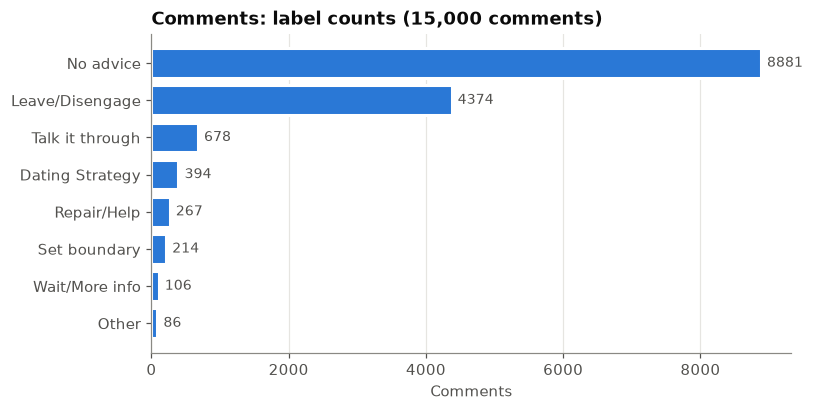

,items,share,median words
label,,,
Early Dating,591,45%,189
Breakups,34,3%,346
Reconciliation,7,1%,453
Communication,94,7%,294
Conflict,179,14%,495
Boundaries,194,15%,399
Trust,33,3%,403
Cheating,51,4%,472
Uncertainty,37,3%,315


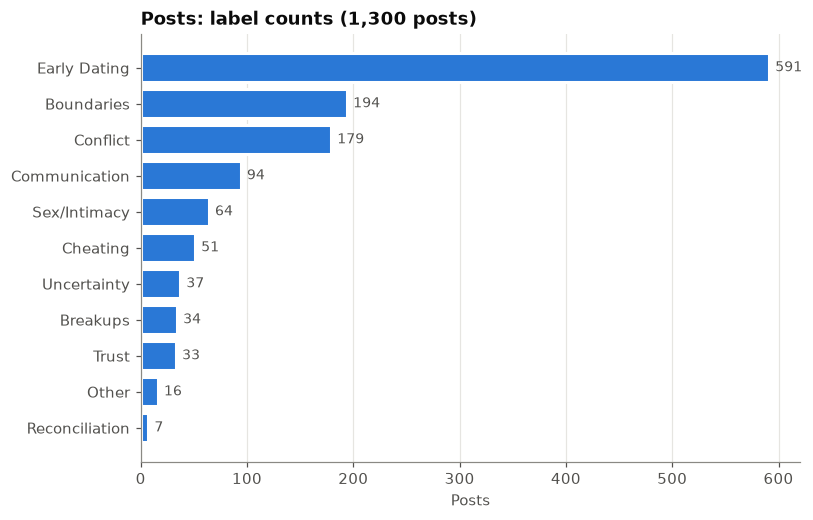

In [3]:
def label_overview(df, labels, what):
    counts = df["label"].value_counts().reindex(labels, fill_value=0)
    display(pd.DataFrame({"items": counts, "share": (counts / counts.sum()).map("{:.0%}".format),
                          "median words": df.groupby("label")["n_words"].median().reindex(labels).round().astype("Int64")}))
    order = counts.sort_values().index
    fig, ax = plt.subplots(figsize=(7.5, 0.33 * len(labels) + 1.2))
    ax.barh(order, counts[order], color=BLUE, edgecolor="white", linewidth=2)
    for i, lab in enumerate(order):
        ax.text(counts[lab] + counts.max() * 0.01, i, str(counts[lab]), va="center", color=INK_2, fontsize=9)
    ax.set_title(f"{what}: label counts ({len(df):,} {what.lower()})")
    ax.set_xlabel(what)
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


label_overview(com, ADVICE_LABELS, "Comments")
label_overview(post, TOPIC_LABELS, "Posts")

- **Comments are very unbalanced:** *No advice* is 59% and *Leave/Disengage* 29%. The other six labels have only 1–5% each. *Other* (86 comments) and *Wait/More info* (106) are the rarest.
- **Length is a clue:** *No advice* comments are short (median 26 words), while the advice labels have 40–105 words.
- **Posts:** *Early Dating* is 45%, *Boundaries* 15% and *Conflict* 14%. *Reconciliation* (7 posts) and *Other* (16) are too small to learn.
- **Posts are long:** median 182–495 words, depending on the topic.

### 2.3 The three labelling rounds
The data was labelled in three rounds:

| Round | Comments | Posts |
| :--- | :--- | :--- |
| round 1 | 500 | 198 |
| round 2 | 1,500 | 597 |
| round 3 | 13,000 | 505 |

All rounds were drawn with the same sampling code, so they should have similar label shares if they were labelled the same way.

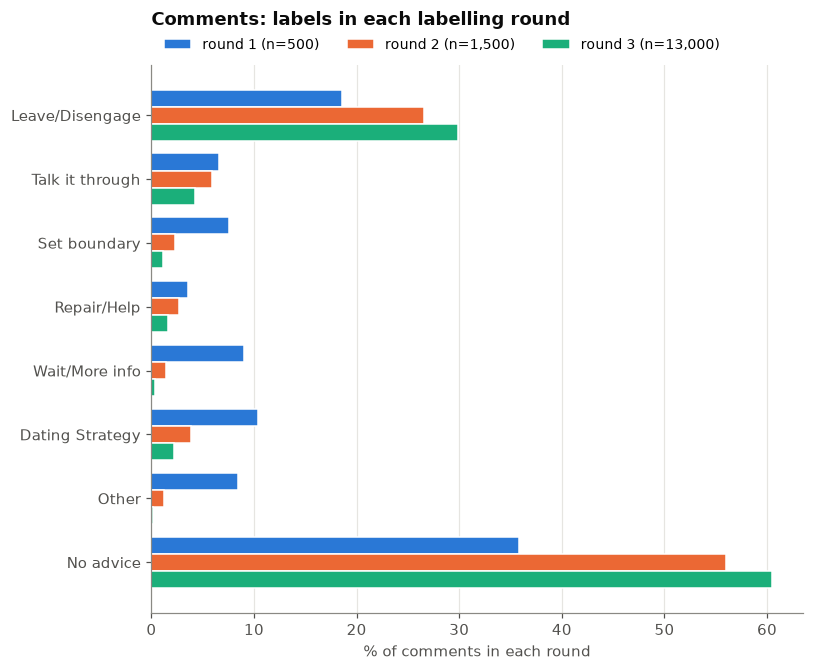

,round 1 (n=500),"round 2 (n=1,500)","round 3 (n=13,000)"
label,,,
Leave/Disengage,18.6,26.6,29.9
Talk it through,6.6,5.9,4.3
Set boundary,7.6,2.3,1.1
Repair/Help,3.6,2.7,1.6
Wait/More info,9.0,1.5,0.3
Dating Strategy,10.4,3.9,2.2
Other,8.4,1.2,0.2
No advice,35.8,56.0,60.5


subreddit,r/dating_advice,r/datingadvice,r/relationship_advice,r/relationshipadvice,median words,with secondary label (%)
batch,,,,,,
round 1,32.0,18.0,18.0,32.0,41.0,14
round 2,32.0,18.0,18.0,32.0,41.0,4
round 3,32.0,18.0,18.0,32.0,41.0,4


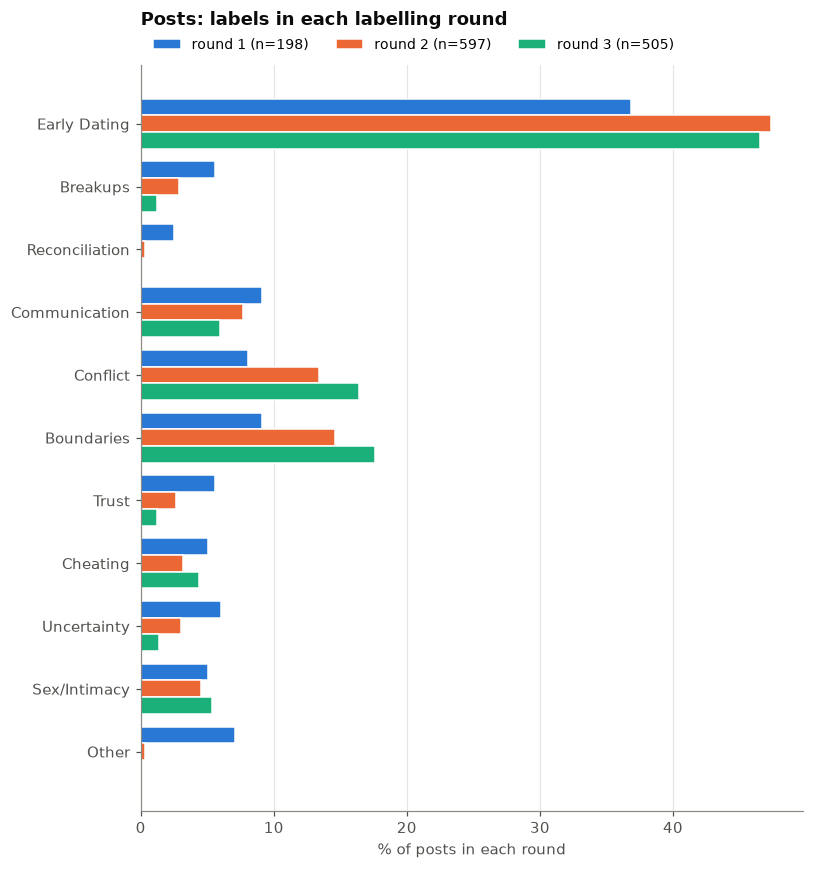

,round 1 (n=198),round 2 (n=597),round 3 (n=505)
label,,,
Early Dating,36.9,47.4,46.5
Breakups,5.6,2.8,1.2
Reconciliation,2.5,0.3,0.0
Communication,9.1,7.7,5.9
Conflict,8.1,13.4,16.4
Boundaries,9.1,14.6,17.6
Trust,5.6,2.7,1.2
Cheating,5.1,3.2,4.4
Uncertainty,6.1,3.0,1.4


subreddit,r/dating_advice,r/datingadvice,r/relationship_advice,r/relationshipadvice,median words,with secondary label (%)
batch,,,,,,
round 1,24.0,26.0,13.0,37.0,282.5,63
round 2,23.0,26.0,13.0,37.0,278.0,30
round 3,23.0,26.0,15.0,36.0,275.0,34


In [4]:
def plot_batch_shares(shares, what):
    """Grouped bars: share of each label in every labelling round."""
    n = shares.shape[1]
    height = 0.8 / n
    y = np.arange(len(shares))
    fig, ax = plt.subplots(figsize=(7.5, 0.6 * len(shares) + 1.4))
    for i, (column, color) in enumerate(zip(shares.columns, [BLUE, ORANGE, AQUA])):
        ax.barh(y + (i - (n - 1) / 2) * height, shares[column] * 100, height=height, color=color,
                edgecolor="white", linewidth=1, label=column)
    ax.set_yticks(y, shares.index)
    ax.invert_yaxis()                       # same order as the table: first label at the top
    ax.set_title(f"{what}: labels in each labelling round", pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=n, fontsize=9)
    ax.set_xlabel(f"% of {what.lower()} in each round")
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


def compare_batches(df, labels, what):
    sizes = df["batch"].value_counts()
    shares = pd.crosstab(df["label"], df["batch"], normalize="columns").reindex(labels, fill_value=0)
    shares.columns = [f"{b} (n={sizes[b]:,})" for b in shares.columns]
    plot_batch_shares(shares, what)
    display((shares * 100).round(1))
    mix = pd.crosstab(df["batch"], df["subreddit"], normalize="index").mul(100).round(0)
    mix["median words"] = df.groupby("batch")["n_words"].median()
    mix["with secondary label (%)"] = df.groupby("batch")["label_secondary"].apply(lambda s: round(s.notna().mean() * 100))
    display(mix)


compare_batches(com, ADVICE_LABELS, "Comments")
compare_batches(post, TOPIC_LABELS, "Posts")

**The texts are alike** (identical subreddit mix and length), **but each round was labelled differently, and round 3 continues the trend of round 2:**
- **Comments:**
  - *No advice* rises 36% → 56% → 61%, and *Leave/Disengage* 19% → 27% → 30%.
  - *Wait/More info* falls 9% → 1.5% → 0.3%, *Other* 8% → 1.2% → 0.2%, *Set boundary* 8% → 2% → 1% and *Dating Strategy* 10% → 4% → 2%.
- **Posts:** *Early Dating* 37% → 47% → 47%, *Boundaries* 9% → 15% → 18%, *Conflict* 8% → 13% → 16%. *Other* and *Reconciliation* disappear completely in round 3.
- **Secondary labels:** comments 14% → 4% → 4%, posts 63% → 30% → 34%.

Round 3 is 87% of the comments, so the models mostly learn its labelling style (see the limitations in section 6).

## 3. Method

### 3.1 Label groupings
Merging similar labels gives each class more examples but less detail (the annotation guidelines allow it). Fewer classes are always easier, even for random guessing, so every grouping is compared with a **chance level**: random guesses in proportion to the class sizes.

| Comments | Change |
| :--- | :--- |
| **8 labels** | none (codebook) |
| **7 labels** | *Repair/Help* → *Talk it through* |
| **6 groups** | *Talk it through* + *Repair/Help* + *Set boundary* → **Stay & work on it** |
| **2 groups** | **Advice** vs. **No advice** |

| Posts | Change |
| :--- | :--- |
| **11 labels** | none (codebook) |
| **8 labels** | *Cheating* → *Trust*; *Uncertainty* and *Reconciliation* → *Other* (the label names in the transformer model's first results) |
| **4 situations** | the research question's situations: **Early Dating**, **Communication & Conflict**, **Trust & Cheating**, **Other** |

In [5]:
SAME_ADVICE = {label: label for label in ADVICE_LABELS}
ADVICE_GROUPINGS = {
    "8 labels": SAME_ADVICE,
    "7 labels": {**SAME_ADVICE, "Repair/Help": "Talk it through"},
    "6 groups": {**SAME_ADVICE, "Talk it through": "Stay & work on it", "Repair/Help": "Stay & work on it",
                 "Set boundary": "Stay & work on it"},
    "2 groups": {label: ("No advice" if label == "No advice" else "Advice") for label in ADVICE_LABELS},
}

SAME_TOPIC = {label: label for label in TOPIC_LABELS}
SITUATIONS = {"Early Dating": "Early Dating", "Communication": "Communication & Conflict",
              "Conflict": "Communication & Conflict", "Trust": "Trust & Cheating", "Cheating": "Trust & Cheating"}
TOPIC_GROUPINGS = {
    "11 labels": SAME_TOPIC,
    "8 labels": {**SAME_TOPIC, "Cheating": "Trust", "Uncertainty": "Other", "Reconciliation": "Other"},
    "4 situations": {label: SITUATIONS.get(label, "Other") for label in TOPIC_LABELS},
}

# One column per grouping, e.g. com["y_6 groups"]
for df, groupings in [(com, ADVICE_GROUPINGS), (post, TOPIC_GROUPINGS)]:
    for name, mapping in groupings.items():
        df[f"y_{name}"] = df["label"].map(mapping)
        assert df[f"y_{name}"].notna().all()

### 3.2 Shared 5-fold cross-validation
Every comment and post gets a `fold` number (1–5):
- **Threads are kept within one fold.** Otherwise the model could recognise a thread instead of the advice.
- **Each label is spread evenly over the folds.**

For fold *k*, the model is trained on the other four folds and predicts fold *k*. After five rounds, every item has one prediction from a model that never saw it. The folds are exported (section 6) so the transformer model uses exactly the same ones.

In [6]:
def assign_folds(df):
    """fold = 1..N_FOLDS; threads kept together, labels spread evenly."""
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    df["fold"] = 0
    for k, (_, idx) in enumerate(splitter.split(df, df["label"], groups=df["thread"]), start=1):
        df.loc[df.index[idx], "fold"] = k
    assert (df["fold"] > 0).all()
    assert df.groupby("thread")["fold"].nunique().max() == 1, "A thread is split across folds!"


assign_folds(com)
assign_folds(post)
display(pd.DataFrame({"comments": com["fold"].value_counts().sort_index(),
                      "posts": post["fold"].value_counts().sort_index()}).rename_axis("fold"))

,comments,posts
fold,,
1,2999,260
2,3001,260
3,2999,260
4,3001,260
5,3000,260


### 3.3 Model and metrics
- **TF–IDF** turns a text into word weights. A word gets a high weight if it is frequent in this text but rare overall.
  - Variants tested: single words, word pairs (1–2-grams), character 2–5-grams, and stopwords kept or removed.
  - Always on: `min_df=2` (ignore words found in only one text) and `sublinear_tf` (dampens repeated words).
- **Logistic regression** learns a weight for every word and label, and predicts the label with the highest score.
  - `class_weight="balanced"` makes mistakes on small labels count more. Its effect is checked once in each experiment.
  - `C` ∈ {0.1, 1, 10} sets how cautious the weights are (smaller = more cautious). It is chosen once per task in Experiment 1 and reused for all label groupings.
- **Metrics:**
  - **precision:** how many items predicted as X really are X;
  - **recall:** how many real X items were found;
  - **F1:** combines precision and recall;
  - **support:** the number of items that really have the label;
  - **macro-F1:** the average F1 over all labels, each label counting equally. This is the main score, because the labels are unbalanced.

Experiments compare settings by the average macro-F1 over the 5 folds. The final results pool all out-of-fold predictions, which is what the transformer comparison uses; the two numbers are nearly identical.

In [7]:
# ---------- Text representations: name -> (function that builds the TF-IDF step, text column) ----------
def word_tfidf(**settings):
    return TfidfVectorizer(lowercase=True, sublinear_tf=True, min_df=2, **settings)


def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=True, sublinear_tf=True, min_df=2)


def words_and_chars():
    return FeatureUnion([("word", word_tfidf(ngram_range=(1, 2))), ("char", char_tfidf())])


APPROACHES = {
    "A. Words": (lambda: word_tfidf(ngram_range=(1, 1)), "text"),
    "B. Words + word pairs": (lambda: word_tfidf(ngram_range=(1, 2)), "text"),
    "C. Words + word pairs, no stopwords": (lambda: word_tfidf(ngram_range=(1, 2), stop_words="english"), "text"),
    "D. Characters": (char_tfidf, "text"),
    "E. Words + word pairs + characters": (words_and_chars, "text"),
}
C_GRID = [0.1, 1, 10]
REFERENCE = "Reference: always the most common label"


# ---------- Training ----------
def make_model(vectorizer, class_weight="balanced", C=1.0):
    return Pipeline([("tfidf", vectorizer),
                     ("clf", LogisticRegression(class_weight=class_weight, C=C, max_iter=5000, random_state=SEED))])


def folds_of(df):
    return PredefinedSplit(df["fold"].values - 1)


def tune(vectorizer, df, label_col, text_col="text", class_weight="balanced"):
    """Choose C on the shared folds (average macro-F1 over the 5 folds)."""
    search = GridSearchCV(make_model(vectorizer, class_weight), {"clf__C": C_GRID}, scoring="f1_macro",
                          cv=folds_of(df), n_jobs=N_JOBS, refit=False)
    return search.fit(df[text_col], df[label_col])


def summarise(search):
    i = search.best_index_
    return [search.best_score_, search.cv_results_["std_test_score"][i], search.best_params_["clf__C"]]


# ---------- Experiment 1: text representations ----------
def experiment_1(df, approaches, label_col):
    rows = {name: summarise(tune(make_vectorizer(), df, label_col, text_col))
            for name, (make_vectorizer, text_col) in approaches.items()}
    table = pd.DataFrame.from_dict(rows, orient="index", columns=["macro-F1", "std", "best C"])
    best = table["macro-F1"].idxmax()
    make_vectorizer, text_col = approaches[best]
    table.loc[f"{best.split('.')[0]} without class weighting"] = summarise(
        tune(make_vectorizer(), df, label_col, text_col, class_weight=None))
    ref = cross_val_score(DummyClassifier(strategy="most_frequent"), df["text"], df[label_col],
                          cv=folds_of(df), scoring="f1_macro")
    table.loc[REFERENCE] = [ref.mean(), ref.std(), np.nan]
    return table.rename_axis("approach").round(3), best


def plot_experiment_1(table, title):
    df = table.drop(index=REFERENCE).sort_values("macro-F1")
    ref = table.loc[REFERENCE, "macro-F1"]
    fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(df) + 1.4))
    ax.barh(df.index, df["macro-F1"], xerr=df["std"], color=BLUE, edgecolor="white", linewidth=2,
            error_kw={"ecolor": INK_MUTED, "elinewidth": 1, "capsize": 3})
    ax.axvline(ref, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.text(ref + 0.005, len(df) - 0.45, "always the most common label", color=INK_2, fontsize=8.5, va="bottom")
    for i, v in enumerate(df["macro-F1"]):
        ax.text(0.01, i, f"{v:.2f}", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_title(title, pad=14)
    ax.set_xlabel("Macro-F1 (mean of 5 folds; line = ± 1 std)")
    ax.set_xlim(0, max(0.5, (df["macro-F1"] + df["std"]).max() + 0.05))
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


# ---------- Experiment 2 and final results: label groupings ----------
def evaluate_groupings(df, groupings, make_vectorizer, text_col, C):
    """Per grouping: predict every item from the model trained on the other folds (settings from Experiment 1)."""
    fold_ids = df["fold"].values
    rows = []
    for name in groupings:
        y_col = f"y_{name}"
        y = df[y_col].values
        pred = cross_val_predict(make_model(make_vectorizer(), C=C), df[text_col], y, cv=folds_of(df), n_jobs=N_JOBS)
        df[f"cv_pred_{name}"] = pred
        chance = cross_val_predict(DummyClassifier(strategy="stratified", random_state=SEED), df[text_col], y, cv=folds_of(df))
        majority = cross_val_predict(DummyClassifier(strategy="most_frequent"), df[text_col], y, cv=folds_of(df))
        per_fold = [f1_score(y[fold_ids == k], pred[fold_ids == k], average="macro", zero_division=0)
                    for k in range(1, N_FOLDS + 1)]
        macro = f1_score(y, pred, average="macro", zero_division=0)
        chance_f1 = f1_score(y, chance, average="macro", zero_division=0)
        rows.append({"grouping": name, "classes": len(set(y)), "smallest class": pd.Series(y).value_counts().min(),
                     "macro-F1": macro, "std across folds": np.std(per_fold), "accuracy": accuracy_score(y, pred),
                     "chance macro-F1": chance_f1, "above chance": macro - chance_f1,
                     "always most common: macro-F1": f1_score(y, majority, average="macro", zero_division=0)})
    return pd.DataFrame(rows).set_index("grouping").round(3)


def plot_groupings(table, title):
    fig, ax = plt.subplots(figsize=(7.5, 0.75 * len(table) + 0.9))
    y = np.arange(len(table))
    ax.barh(y + 0.2, table["macro-F1"], height=0.38, color=BLUE, edgecolor="white", linewidth=2, label="Model")
    ax.barh(y - 0.2, table["chance macro-F1"], height=0.38, color=ORANGE, edgecolor="white", linewidth=2, label="Chance level")
    for i, (m, c) in enumerate(zip(table["macro-F1"], table["chance macro-F1"])):
        ax.text(m + 0.01, i + 0.2, f"{m:.2f}", va="center", color=INK_2, fontsize=9)
        ax.text(c + 0.01, i - 0.2, f"{c:.2f}", va="center", color=INK_2, fontsize=9)
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Macro-F1 (all out-of-fold predictions)")
    ax.set_xlim(0, 1); ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()


# ---------- Per-label results ----------
def label_order(mapping):
    """The labels of a grouping in codebook order, with 'Other' and 'No advice' moved to the end."""
    labels = list(dict.fromkeys(mapping.values()))
    last = [l for l in ("Other", "No advice") if l in labels]
    return [l for l in labels if l not in last] + last


def per_label_table(y_true, y_pred, labels):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    table = pd.DataFrame({"precision": p, "recall": r, "F1": f, "support": s}, index=labels)
    table.loc["macro average"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    return table.round(2).astype({"support": int})


def show_per_label_tables(df, groupings):
    for name, mapping in groupings.items():
        display(Markdown(f"**{name}**"))
        display(per_label_table(df[f"y_{name}"], df[f"cv_pred_{name}"], label_order(mapping)))


def plot_confusion(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    n = len(labels)
    fig, ax = plt.subplots(figsize=(0.8 * n + 3.2, 0.62 * n + 2.0))
    ax.imshow(share, cmap=SEQ_BLUES, vmin=0, vmax=1)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if share[i, j] > 0.55 else (INK if cm[i, j] else INK_MUTED))
    ax.set_xticks(range(n), labels, rotation=35, ha="right")
    ax.set_yticks(range(n), labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Annotated")
    ax.set_title(title, pad=20)
    ax.text(0, 1.015, "Numbers = counts · shade = share of the annotated row", transform=ax.transAxes,
            va="bottom", color=INK_2, fontsize=8.5)
    for side in ax.spines.values():
        side.set_visible(False)
    plt.tight_layout(); plt.show()


# ---------- Inside the model ----------
def top_words(df, make_vectorizer, text_col, y_col, C, n=12):
    """Train on all items and list the n words / word pairs with the highest weight per label."""
    model = make_model(make_vectorizer(), C=C).fit(df[text_col], df[y_col])
    vectorizer, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    names = vectorizer.get_feature_names_out().astype(str)
    weights = clf.coef_
    if isinstance(vectorizer, FeatureUnion):            # words + characters: show only the word part
        keep = np.char.startswith(names, "word__")
        names, weights = np.char.replace(names[keep], "word__", ""), weights[:, keep]
    return pd.DataFrame({label: names[np.argsort(weights[k])[::-1][:n]] for k, label in enumerate(clf.classes_)},
                        index=pd.RangeIndex(1, n + 1, name="rank"))


# ---------- Mistakes ----------
def look_at_mistakes(df, grouping, mapping, show_col, show_name, n_examples=10):
    y_col, p_col = f"y_{grouping}", f"cv_pred_{grouping}"
    errors = df[df[y_col] != df[p_col]]
    print(f"Wrong predictions ({grouping}): {len(errors):,} of {len(df):,}\n")
    print("Most common confusions:")
    display(errors.groupby([y_col, p_col]).size().sort_values(ascending=False).head(8)
            .rename("count").reset_index().rename(columns={y_col: "annotated", p_col: "predicted"}))
    secondary = errors["label_secondary"].map(mapping)
    has_secondary = secondary.notna()
    print(f"Mistakes on items with a secondary label: {has_secondary.sum()}; "
          f"in {(errors.loc[has_secondary, p_col] == secondary[has_secondary]).sum()} of them the model predicted that secondary label.")
    if SHOW_TEXT_EXAMPLES:
        sample = errors.sample(min(n_examples, len(errors)), random_state=SEED)
        display(sample.assign(**{show_name: sample[show_col].map(snippet)})[[y_col, p_col, show_name]]
                .rename(columns={y_col: "annotated", p_col: "predicted"}).reset_index(drop=True))

---
## 4. Comments: advice type

### 4.1 Experiment 1: text representations
Five representations on the 8 labels, each with balanced class weights and the best `C`. The best one is also run without class weighting.

| Approach | Description |
| :--- | :--- |
| A. Words | single words |
| B. Words + word pairs | 1–2-grams |
| C. Words + word pairs, no stopwords | like B, without common English words |
| D. Characters | 2–5-character runs |
| E. Words + word pairs + characters | B and D combined |

,macro-F1,std,best C
approach,,,
A. Words,0.548,0.018,10.0
B. Words + word pairs,0.573,0.026,10.0
"C. Words + word pairs, no stopwords",0.480,0.016,10.0
D. Characters,0.532,0.019,10.0
E. Words + word pairs + characters,0.574,0.019,10.0
E without class weighting,0.500,0.018,10.0
Reference: always the most common label,0.093,0.000,NaN


Best approach: E. Words + word pairs + characters


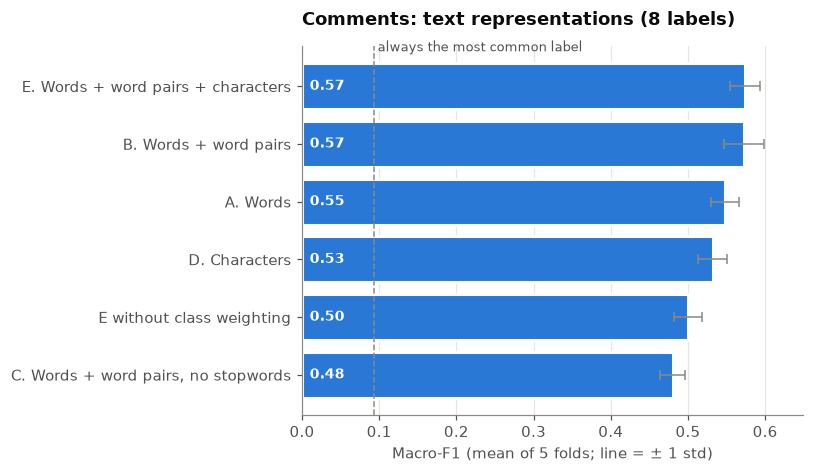

In [8]:
exp1_A, BEST_A = experiment_1(com, APPROACHES, "y_8 labels")
display(exp1_A)
print(f"Best approach: {BEST_A}")
plot_experiment_1(exp1_A, "Comments: text representations (8 labels)")

- **E (words + word pairs + characters) and B (words + word pairs) are tied at 0.57.** Single words reach 0.55 and characters alone 0.53.
- **Removing stopwords hurts** (0.57 → 0.48). *you*, *if* and *do you* separate advice from stories and questions.
- **Class weighting helps:** E scores 0.50 without it and 0.57 with it.
- **The best C is 10 for every approach,** the largest value tried. With 15,000 comments the model can use larger weights without memorising.
- **All approaches are far above always predicting *No advice*** (0.09).

### 4.2 Experiment 2 and results: label groupings
The best representation and `C` from Experiment 1 on each grouping. Every item is predicted by the model trained on the other four folds.

,classes,smallest class,macro-F1,std across folds,accuracy,chance macro-F1,above chance,always most common: macro-F1
grouping,,,,,,,,
8 labels,8,86,0.575,0.019,0.858,0.122,0.453,0.093
7 labels,7,86,0.556,0.019,0.859,0.140,0.416,0.106
6 groups,6,86,0.552,0.021,0.860,0.163,0.389,0.124
2 groups,2,6119,0.897,0.004,0.900,0.505,0.393,0.372


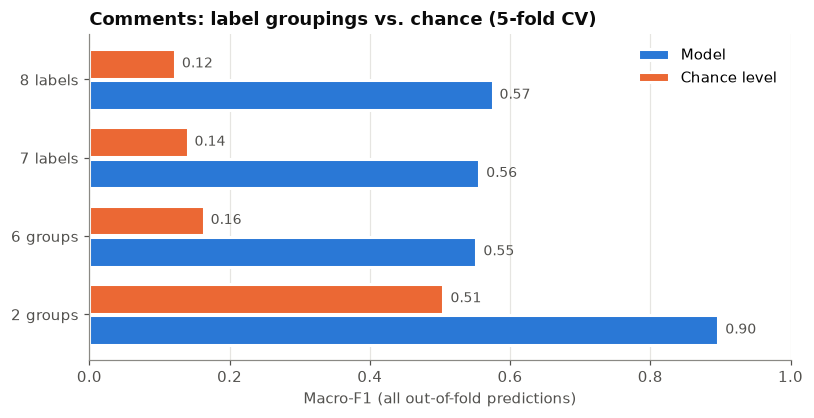

In [9]:
C_A = exp1_A.loc[BEST_A, "best C"]
results_A = evaluate_groupings(com, ADVICE_GROUPINGS, *APPROACHES[BEST_A], C=C_A)
display(results_A)
plot_groupings(results_A, "Comments: label groupings vs. chance (5-fold CV)")

- **8 labels: macro-F1 0.57** (std 0.02 across folds, accuracy 0.86), which is **0.45 above chance**.
- **Merging doesn't help:** 7 labels score 0.56 and 6 groups 0.55. **The 8 original labels stay the main result.**
- **Advice vs. no advice: 0.90** (chance 0.50).

### 4.3 Per-label precision, recall and F1
Support is the number of comments that really have the label; labels with small support have unreliable scores. In the confusion matrices, rows are the annotated labels, columns the predictions, and the diagonal holds the correct predictions.

**8 labels**

,precision,recall,F1,support
Leave/Disengage,0.79,0.87,0.83,4374
Talk it through,0.65,0.72,0.69,678
Set boundary,0.66,0.53,0.59,214
Repair/Help,0.71,0.70,0.70,267
Wait/More info,0.67,0.11,0.19,106
Dating Strategy,0.59,0.64,0.61,394
Other,0.43,0.03,0.06,86
No advice,0.94,0.90,0.92,8881
macro average,0.68,0.56,0.57,15000


**7 labels**

,precision,recall,F1,support
Leave/Disengage,0.79,0.87,0.83,4374
Talk it through,0.68,0.72,0.70,945
Set boundary,0.66,0.51,0.58,214
Wait/More info,0.67,0.11,0.19,106
Dating Strategy,0.60,0.62,0.61,394
Other,0.33,0.03,0.06,86
No advice,0.93,0.90,0.92,8881
macro average,0.67,0.54,0.56,15000


**6 groups**

,precision,recall,F1,support
Leave/Disengage,0.80,0.86,0.83,4374
Stay & work on it,0.68,0.72,0.70,1159
Wait/More info,0.71,0.11,0.20,106
Dating Strategy,0.59,0.62,0.61,394
Other,0.38,0.03,0.06,86
No advice,0.94,0.90,0.92,8881
macro average,0.68,0.54,0.55,15000


**2 groups**

,precision,recall,F1,support
Advice,0.86,0.91,0.88,6119
No advice,0.93,0.90,0.91,8881
macro average,0.89,0.90,0.90,15000


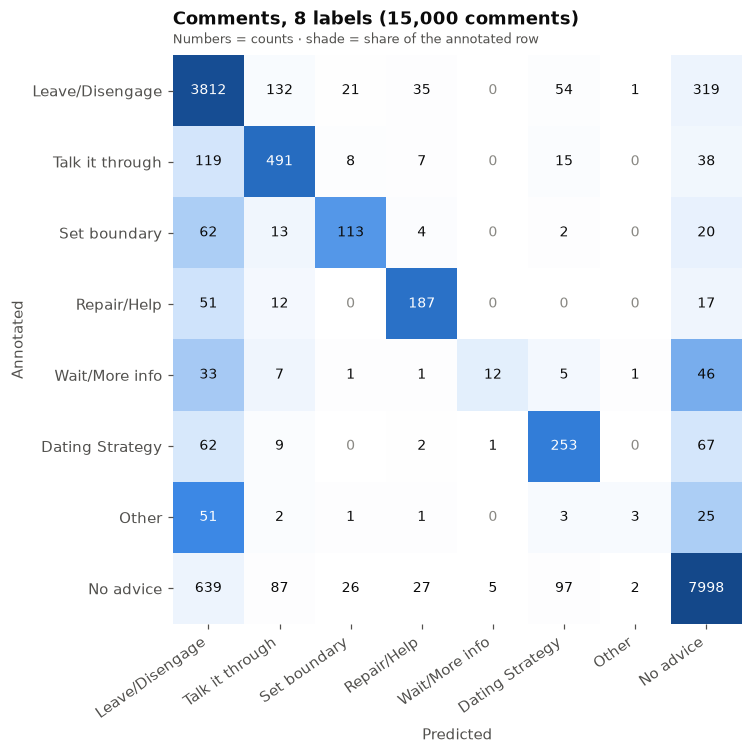

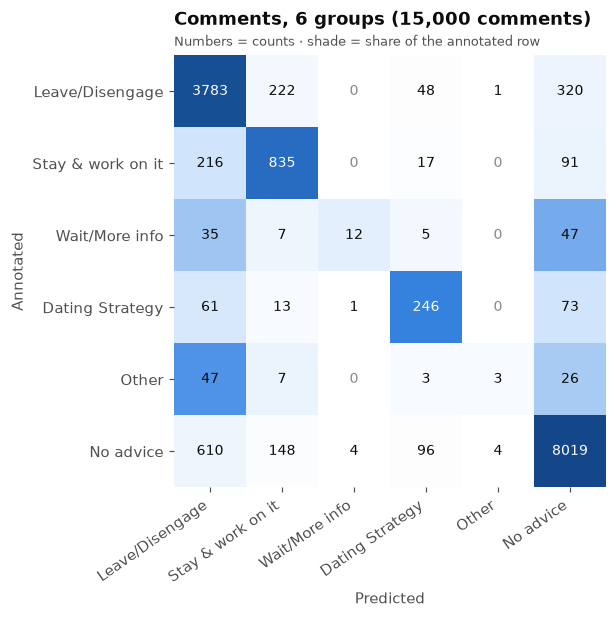

In [10]:
show_per_label_tables(com, ADVICE_GROUPINGS)
plot_confusion(com["y_8 labels"], com["cv_pred_8 labels"], ADVICE_LABELS, f"Comments, 8 labels ({len(com):,} comments)")
plot_confusion(com["y_6 groups"], com["cv_pred_6 groups"], label_order(ADVICE_GROUPINGS["6 groups"]),
               f"Comments, 6 groups ({len(com):,} comments)")

- **Good:** *No advice* (F1 0.92), *Leave/Disengage* (0.83), *Repair/Help* (0.70) and *Talk it through* (0.69).
- **Medium:** *Dating Strategy* (0.61) and *Set boundary* (0.59).
- **Poor:** *Wait/More info* (0.19, recall 0.11) and *Other* (0.06, recall 0.03). After round 1 these labels were hardly used, so the model sees few and inconsistent examples.
- **6 groups:** the merged *Stay & work on it* reaches 0.70.
- **Biggest confusions:** *No advice* ↔ *Leave/Disengage* (639 and 319 comments) and *Leave/Disengage* ↔ *Talk it through* (132 and 119).

### 4.4 Top words and mistakes (8 labels)
The 12 words or word pairs with the highest weight per label (model trained on all comments; word part only), followed by the most common confusions, accuracy by comment length and 10 random wrong predictions.

In [11]:
display(top_words(com, *APPROACHES[BEST_A], "y_8 labels", C_A))

look_at_mistakes(com, "8 labels", ADVICE_GROUPINGS["8 labels"], "bodyText", "comment")
length = pd.cut(com["n_words"], [0, 20, 60, np.inf], labels=["short (≤20 words)", "medium (21–60)", "long (>60)"]).rename("length")
correct = com["cv_pred_8 labels"] == com["y_8 labels"]
print("\nAccuracy by comment length:")
display(correct.groupby(length, observed=True).agg(comments="size", accuracy="mean").round(2))

,Dating Strategy,Leave/Disengage,No advice,Other,Repair/Help,Set boundary,Talk it through,Wait/More info
rank,,,,,,,,
1,date,move on,to the,love yourself,therapy,boundaries,talk to,are you
2,her out,break up,for me,cheat,therapist,say no,tell,old are
3,on date,move,was,yourself,she needs,set,talk,updates
4,go on,you are,men,to love,counseling,boundary,tell him,how old
5,women,someone who,being,love,help,no,communicate,you paying
6,ask her,on,like he,your gut,go to,he to,tell her,do you
7,apps,break,he was,you next,needs,come without,to him,more info
8,out,you,the wrong,gut,to therapy,she can,sit down,take it
9,if you,leave,with me,for the,couples,what you,just tell,how are


Wrong predictions (8 labels): 2,131 of 15,000

Most common confusions:


,annotated,predicted,count
0,No advice,Leave/Disengage,639
1,Leave/Disengage,No advice,319
2,Leave/Disengage,Talk it through,132
3,Talk it through,Leave/Disengage,119
4,No advice,Dating Strategy,97
5,No advice,Talk it through,87
6,Dating Strategy,No advice,67
7,Dating Strategy,Leave/Disengage,62


Mistakes on items with a secondary label: 180; in 89 of them the model predicted that secondary label.


,annotated,predicted,comment
0,Leave/Disengage,No advice,Did he ever ask you a question? Did you feel like he was interested in your life as well? I wouldn't be too frazzled by the undertaker stuff but it do…
1,No advice,Leave/Disengage,"66M The attraction that you’re referring to is often called “chemistry.” And without it, it is simply not possible to have a romantic relationship of …"
2,Leave/Disengage,Talk it through,I don’t know why you’re so concerned about hanging on to this friendship when she’s causing drama and making everything about her. Tell her that betwe…
3,Repair/Help,No advice,"Tbh this sounds like a ppd and she should be in therapy or it can get worse. I had almost the same issue as your gf. When my son was born, I had ppd a…"
4,Set boundary,Leave/Disengage,Is she still friends with the ex? Does she openly hang out with him like she would any other friend or is the location sharing their only form of stay…
5,Leave/Disengage,No advice,"I get and appreciate the sentiment of this post, but I had plenty of crushes who told me how safe and comfortable they feel around me and how differen…"
6,No advice,Leave/Disengage,"Somebody can be honest as the day is long but if he's a dimwitted puppydog and doesn't wash his butt or brush his teeth, I'm not going to hang out wit…"
7,Leave/Disengage,No advice,Look into absence seizures. I had them and didn’t even know I was losing time. A nurse friend caught them and came with me to the doctors. It was diag…
8,Set boundary,Leave/Disengage,"I was seeing someone who I genuinely liked and felt they liked me too but the same level of care and effort just wasn’t there, so 3 months in I said t…"
9,No advice,Talk it through,"If the smell is her coat it’s possible she’s nose blind to the smell of it at this point. I would just mention it casually, that maybe she should cons…"



Accuracy by comment length:


,comments,accuracy
length,,
short (≤20 words),4185,0.92
medium (21–60),5414,0.87
long (>60),5401,0.79


- **Top words are sensible:**
  - *Dating Strategy*: date, ask her, apps.
  - *Leave/Disengage*: move on, break up, walk away.
  - *Talk it through*: talk to, tell him, communicate, sit down.
  - *Set boundary*: boundaries, say no.
  - *Repair/Help*: therapy, counseling, couples, work on.
  - *Wait/More info*: questions and requests (*are you*, *how old*, *updates*, *more info*).
  - *No advice*: stories and reactions.
  - *Other* has no clear vocabulary of its own (*love yourself*, *your gut*).
- **2,131 of 15,000 comments are wrong (14%).** Accuracy falls with length: 0.92 for short comments, 0.87 for medium and 0.79 for long ones.
- **Partly right:** in 89 of the 180 errors on comments with a secondary label, the model predicted that second label.
- **Typical problems in the sample:**
  - **personal stories read as advice or the other way round** (rows 5 and 8);
  - **mixed advice** (row 2 suggests leaving the friendship but also *"Tell her…"*, so the model picks *Talk it through*);
  - **advice written as questions** (rows 0 and 4 ask the poster questions and get the wrong label);
  - **debatable labels** (row 9, *"I would just mention it casually"*, is labelled *No advice*; row 7, *"Look into absence seizures"*, is labelled *Leave/Disengage*).

---
## 5. Posts: topic
The same steps for posts. Posts are much longer than comments (median roughly 270 words vs. 41) and there are fewer of them.

### 5.1 Experiment 1: text representations
The same five approaches on the 11 labels, plus **F. Title only** (words + word pairs from the title alone).

,macro-F1,std,best C
approach,,,
A. Words,0.388,0.029,1.0
B. Words + word pairs,0.373,0.045,0.1
"C. Words + word pairs, no stopwords",0.394,0.039,0.1
D. Characters,0.370,0.030,1.0
E. Words + word pairs + characters,0.375,0.048,0.1
F. Title only (words + word pairs),0.309,0.017,1.0
C without class weighting,0.247,0.033,10.0
Reference: always the most common label,0.057,0.000,NaN


Best approach: C. Words + word pairs, no stopwords


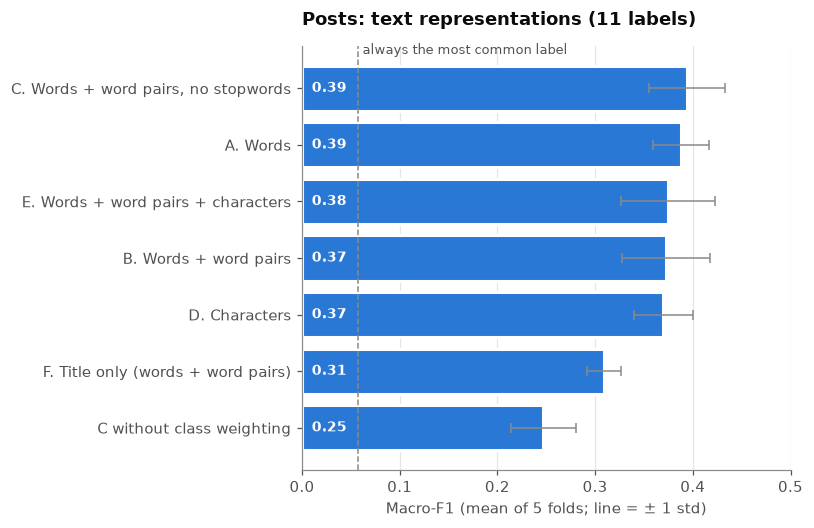

In [12]:
POST_APPROACHES = {**APPROACHES,
                   "F. Title only (words + word pairs)": (lambda: word_tfidf(ngram_range=(1, 2)), "title_text")}
exp1_B, BEST_B = experiment_1(post, POST_APPROACHES, "y_11 labels")
display(exp1_B)
print(f"Best approach: {BEST_B}")
plot_experiment_1(exp1_B, "Posts: text representations (11 labels)")

- **C (word pairs without stopwords) is best at 0.39,** but single words (0.39) and the other approaches (0.37–0.38) are within the fold-to-fold spread. Simple word counts are enough for posts.
- **The title alone is clearly worse** (0.31). Most of the topic information is in the post text.
- **Class weighting is essential:** 0.25 without it.
- **The best C is 0.1:** posts are long and few, so the model needs to stay cautious.

### 5.2 Experiment 2 and results: label groupings

,classes,smallest class,macro-F1,std across folds,accuracy,chance macro-F1,above chance,always most common: macro-F1
grouping,,,,,,,,
11 labels,11,7,0.397,0.039,0.675,0.087,0.310,0.057
8 labels,8,34,0.492,0.048,0.691,0.128,0.364,0.078
4 situations,4,84,0.664,0.011,0.740,0.246,0.418,0.156


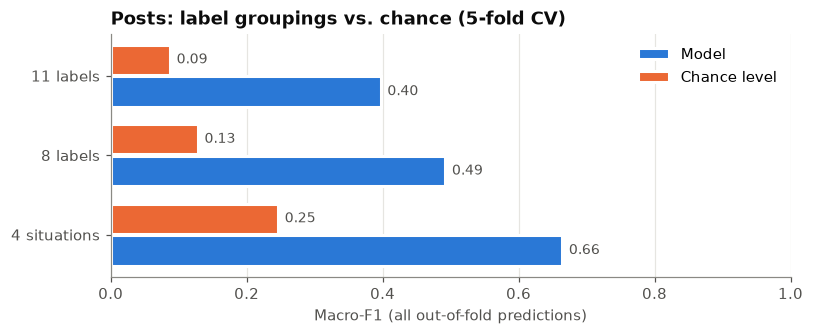

In [13]:
C_B = exp1_B.loc[BEST_B, "best C"]
results_B = evaluate_groupings(post, TOPIC_GROUPINGS, *POST_APPROACHES[BEST_B], C=C_B)
display(results_B)
plot_groupings(results_B, "Posts: label groupings vs. chance (5-fold CV)")

- **11 labels 0.40, 8 labels 0.49, 4 situations 0.66** (accuracy 0.74). Above chance that is +0.31, +0.36 and +0.42.
- **Merging helps for posts,** because the small topics overlap (Trust/Cheating, Communication/Conflict).
- **Use 4 situations** for the research question and **8 labels** to compare with the transformer model.

### 5.3 Per-label precision, recall and F1

**11 labels**

,precision,recall,F1,support
Early Dating,0.89,0.90,0.89,591
Breakups,0.13,0.06,0.08,34
Reconciliation,0.00,0.00,0.00,7
Communication,0.46,0.40,0.43,94
Conflict,0.57,0.65,0.61,179
Boundaries,0.64,0.35,0.45,194
Trust,0.33,0.39,0.36,33
Cheating,0.43,0.78,0.56,51
Uncertainty,0.35,0.49,0.41,37
Sex/Intimacy,0.47,0.73,0.58,64


**8 labels**

,precision,recall,F1,support
Early Dating,0.87,0.91,0.89,591
Breakups,0.22,0.06,0.09,34
Communication,0.48,0.36,0.41,94
Conflict,0.55,0.71,0.62,179
Boundaries,0.62,0.42,0.50,194
Trust,0.50,0.67,0.57,84
Sex/Intimacy,0.50,0.69,0.58,64
Other,0.36,0.22,0.27,60
macro average,0.51,0.50,0.49,1300


**4 situations**

,precision,recall,F1,support
Early Dating,0.86,0.94,0.90,591
Communication & Conflict,0.60,0.72,0.66,273
Trust & Cheating,0.54,0.58,0.56,84
Other,0.69,0.45,0.54,352
macro average,0.67,0.67,0.66,1300


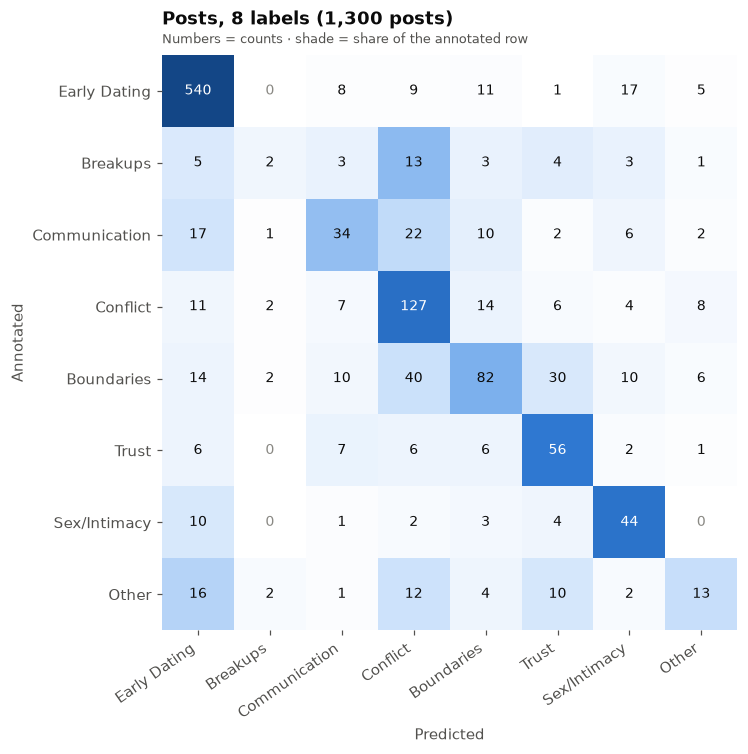

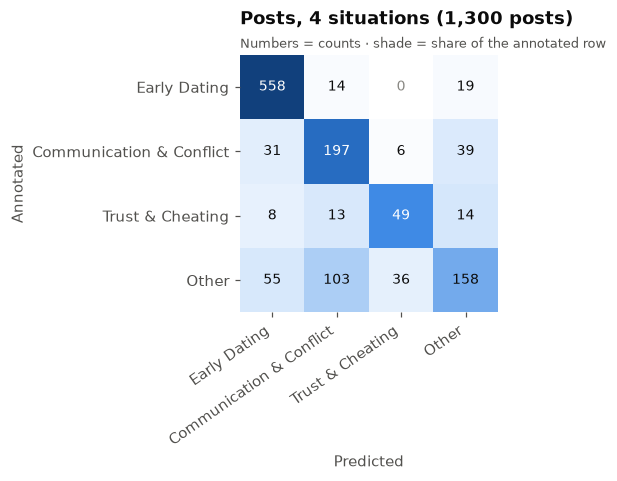

In [14]:
show_per_label_tables(post, TOPIC_GROUPINGS)
plot_confusion(post["y_8 labels"], post["cv_pred_8 labels"], label_order(TOPIC_GROUPINGS["8 labels"]),
               f"Posts, 8 labels ({len(post):,} posts)")
plot_confusion(post["y_4 situations"], post["cv_pred_4 situations"], label_order(TOPIC_GROUPINGS["4 situations"]),
               f"Posts, 4 situations ({len(post):,} posts)")

- ***Early Dating* is found very reliably** (F1 0.89–0.90, recall 0.90–0.94).
- **8 labels:**
  - *Conflict* 0.62, *Sex/Intimacy* 0.58, *Trust* 0.57, *Boundaries* 0.50, *Communication* 0.41;
  - weak: *Other* 0.27 and *Breakups* 0.09 (2 of 34 found).
- **11 labels:** *Cheating* is found well (recall 0.78), but *Reconciliation* and *Other* are never found.
- **4 situations:** Early Dating 0.90, Communication & Conflict 0.66, Trust & Cheating 0.56, Other 0.54.

### 5.4 Top words and mistakes (8 labels)
The examples show the post title only.

In [15]:
display(top_words(post, *POST_APPROACHES[BEST_B], "y_8 labels", C_B))
look_at_mistakes(post, "8 labels", TOPIC_GROUPINGS["8 labels"], "title", "post title")

,Boundaries,Breakups,Communication,Conflict,Early Dating,Other,Sex/Intimacy,Trust
rank,,,,,,,,
1,boundaries,end,boyfriend,argument,date,marriage,sex,cheated
2,friend,breaking,bring,living,dating,visa,porn,cheating
3,sister,break,bf,money,guy,future,having sex,trust
4,uncomfortable,end relationship,makes,work,men,overthinking,intimacy,phone
5,mom,break bf,talk,home,women,incompatible,sex life,wife
6,gf,house,20f,house,interested,married,sexual,told
7,girlfriend,guys ended,shuts,upset,girl,family,sexually,affair
8,friends,grass,ask,pay,apps,currently,sex time,saw
9,baby,leave,tldr,job,guys,financially,insecure,lying


Wrong predictions (8 labels): 402 of 1,300

Most common confusions:


,annotated,predicted,count
0,Boundaries,Conflict,40
1,Boundaries,Trust,30
2,Communication,Conflict,22
3,Communication,Early Dating,17
4,Early Dating,Sex/Intimacy,17
5,Other,Early Dating,16
6,Boundaries,Early Dating,14
7,Conflict,Boundaries,14


Mistakes on items with a secondary label: 200; in 85 of them the model predicted that secondary label.


,annotated,predicted,post title
0,Sex/Intimacy,Early Dating,Girlfriend’s medical note says “currently sexually active with 2 male partners” even though we’re exclusive. Am I overreacting?
1,Sex/Intimacy,Early Dating,Not making a sound when finishing
2,Other,Conflict,"I’m a [38F] wondering if my [28M] boyfriend of 2 years, is being irresponsible with his money."
3,Boundaries,Conflict,gf's mom wants me [21M] to talk to my gf [21F] about weightloss.
4,Boundaries,Sex/Intimacy,Should I [41M] sleep with my best friend [39F] even though she has terminal cancer?
5,Communication,Conflict,I [25F] am debating if not being attracted to my fiancé [29M] is a significant issue
6,Communication,Early Dating,48F - Why is it impossible for men (~50M) to feel love towards me?
7,Other,Conflict,does my boyfriend [29M] and i [27F] have a communication mismatch or just incompatible?
8,Early Dating,Communication,how to tell someone im not ready for a relationship?
9,Boundaries,Communication,My [53F] husband [65M] refuses to lock our doors at night.


- **Top words are clear topic signals:**
  - *Trust*: cheated, affair, lying, phone.
  - *Sex/Intimacy*: sex, porn, intimacy.
  - *Early Dating*: date, interested, apps, meet.
  - *Conflict*: argument, living, money, cooking.
  - *Breakups*: breaking, end relationship, regret.
  - *Other*: marriage, visa, future, financially.
  - *Boundaries*: friend, sister, mom, uncomfortable, controlling.
  - *Communication* has vaguer words, which matches its lower F1.
- **402 of 1,300 posts are wrong.** In 85 of the 200 errors on posts with a secondary topic, the model predicted that topic.
- **Most errors are between overlapping topics:** *Boundaries* → *Conflict* (40) and → *Trust* (30), *Communication* → *Conflict* (22).
- **The sample shows borderline cases:**
  - row 0 (*"medical note says sexually active with 2 male partners even though we're exclusive"*) is labelled *Sex/Intimacy* but is arguably about trust;
  - row 7 (*"communication mismatch or just incompatible?"*) is labelled *Other*;
  - row 8 (*"how to tell someone I'm not ready for a relationship?"*) could be Early Dating or Communication.

---
## 6. Export and summary

### 6.1 Export for the transformer model
These files go to `data/model_outputs/`. They contain IDs and labels only, no Reddit text, and they are shared directly rather than committed to GitHub.

| File | Content |
| :--- | :--- |
| `comment_split.csv` | the 2,000 comments with their `fold` (1–5), `label`, `label_secondary` and every grouping (`y_…`) |
| `post_split.csv` | the same for the 800 posts |
| `comment_cv_predictions_baseline.csv` | the baseline's out-of-fold prediction for every comment in every grouping (`cv_pred_…`) |
| `post_cv_predictions_baseline.csv` | the same for the posts |

In [16]:
def split_file(df, groupings, id_cols):
    return df[id_cols + ["subreddit", "fold", "label", "label_secondary"] + [f"y_{g}" for g in groupings]]


def cv_predictions_file(df, groupings, id_cols):
    return df[id_cols + ["fold"] + [f"y_{g}" for g in groupings] + [f"cv_pred_{g}" for g in groupings]]


exports = {
    "comment_split.csv": split_file(com, ADVICE_GROUPINGS, ["submissionId", "parentPostId"]),
    "post_split.csv": split_file(post, TOPIC_GROUPINGS, ["submissionId"]),
    "comment_cv_predictions_baseline.csv": cv_predictions_file(com, ADVICE_GROUPINGS, ["submissionId", "parentPostId"]),
    "post_cv_predictions_baseline.csv": cv_predictions_file(post, TOPIC_GROUPINGS, ["submissionId"]),
}
for filename, df in exports.items():
    assert not {"bodyText", "title", "text", "title_text"} & set(df.columns)   # never export Reddit text
    df.to_csv(OUT_DIR / filename, index=False)
    print(f"Saved {filename:<40} {len(df):>5,} rows -> {(OUT_DIR / filename).relative_to(ROOT).as_posix()}")

Saved comment_split.csv                        15,000 rows -> data/model_outputs/comment_split.csv
Saved post_split.csv                           1,300 rows -> data/model_outputs/post_split.csv
Saved comment_cv_predictions_baseline.csv      15,000 rows -> data/model_outputs/comment_cv_predictions_baseline.csv
Saved post_cv_predictions_baseline.csv         1,300 rows -> data/model_outputs/post_cv_predictions_baseline.csv


### 6.2 Summary

**Results (5-fold cross-validation, macro-F1)**

| Task | Grouping | Model | Chance level | Always the most common label |
| :--- | :--- | :--- | :--- | :--- |
| Comments | **8 labels (main)** | **0.57** | 0.12 | 0.09 |
| Comments | 7 labels | 0.56 | 0.14 | 0.11 |
| Comments | 6 groups | 0.55 | 0.16 | 0.12 |
| Comments | 2 groups (advice vs. no advice) | 0.90 | 0.50 | 0.37 |
| Posts | 11 labels | 0.40 | 0.09 | 0.06 |
| Posts | 8 labels | 0.49 | 0.13 | 0.08 |
| Posts | **4 situations (research question)** | **0.66** | 0.25 | 0.16 |

**Takeaways**
1. **Both baselines clearly beat chance.**
   - Comments: strong on *advice vs. no advice* (0.90) and the large labels; weak on *Wait/More info* and *Other*, which were hardly used after round 1.
   - Posts: strong on *Early Dating*; weak on *Breakups* and *Other*, and confused between overlapping topics (Boundaries / Conflict / Trust).
2. **Best settings:**
   - **comments:** words + word pairs + characters, C = 10;
   - **posts:** word pairs without stopwords from title + text, C = 0.1;
   - **both:** balanced class weights.
3. **Merging labels doesn't help comments** (keep the 8 labels) **but helps posts** (use the 4 situations for the research question).
4. **The rare labels *Wait/More info* and *Other* need more consistent examples,** not just more data.

**For the transformer model**
- **Use the `fold` column** in `comment_split.csv` and `post_split.csv`:
  - for fold *k*, train on the other folds (column `label` or a `y_…` grouping) and predict fold *k*;
  - repeat for k = 1–5.
- **Compare** the pooled out-of-fold macro-F1 and the per-label tables with sections 4 and 5, and compare errors item by item with the `*_cv_predictions_baseline.csv` files.

### 6.3 Limitations
- **AI labels:** the labels come from an AI annotator and are not checked by a person, so the scores measure agreement with the AI labels.
- **Inconsistent rounds:** the three labelling rounds were labelled differently (section 2.3). Round 3 is 87% of the comments, so the model mostly learns and is graded on round 3's style, and it is clearly less accurate on round 1 items.
- **Rare labels barely learnable:** *Wait/More info* and *Other* (comments) and *Reconciliation* and *Other* (posts) have too few, mostly round-1 examples.
- **Slightly optimistic scores:** `C` and the text representation were chosen on the same folds that give the final scores. The same applies to the transformer if it is tuned on these folds.
- **One label per item:** comments with several kinds of advice and posts with several topics are only partly captured.
- **No context:** the comment model doesn't see the post it answers.
- **Mixed sample:** four subreddits are mixed, and most posts in the dataset are from 2026.

### 6.4 Failure journal
| Problem | What we did |
| :--- | :--- |
| The first version went beyond the role | Rescoped to the team plan; post topics were added later on request |
| The notebook took about 7.5 minutes and had 22 sections | Kept only the shared 5-fold cross-validation, in 6 sections |
| The data grew to 15,000 comments (about 15 minutes to run, high memory use) | `C` is chosen once per task in Experiment 1; `N_JOBS = 5` keeps memory use safe |
| Small labels were ignored | `class_weight="balanced"` |
| Stopword removal hurt comments but helped posts | Chose per task by experiment |
| Adding the post as context to comments, the top comments as context to posts, length features and a two-step model | Tested separately; none improved macro-F1 |
| The labelling rounds are inconsistent | Documented as a limitation and in the round chart; asked the annotator |
| Too few examples of rare labels | Merged in the 8-label and 4-situation post groupings |